In [26]:
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [27]:
manager = "Manager Agent"

agents = ["Agent A", "Agent B", "Agent C"]

tasks = {
    "T1": {"location": "Library", "resource": "R1"},
    "T2": {"location": "Hospital", "resource": "R2"},
    "T3": {"location": "College", "resource": "R1"},
    "T4": {"location": "Market", "resource": "R3"},
    "T5": {"location": "Airport", "resource": "R2"},
    "T6": {"location": "Station", "resource": "R3"}
}

# Cost and time required by each agent for every task
costs = {
    "Agent A": [20, 35, 25, 40, 45, 30],
    "Agent B": [25, 30, 20, 35, 40, 25],
    "Agent C": [30, 25, 30, 25, 35, 20]
}

times = {
    "Agent A": [15, 25, 20, 30, 35, 25],
    "Agent B": [20, 20, 15, 25, 30, 20],
    "Agent C": [25, 15, 25, 20, 25, 15]
}

print("Manager:", manager)
print("Delivery Agents:", agents)
print("Number of tasks:", len(tasks))

Manager: Manager Agent
Delivery Agents: ['Agent A', 'Agent B', 'Agent C']
Number of tasks: 6


In [28]:
rows = []

for task_index, task in enumerate(tasks):
    for agent in agents:
        rows.append({
            "Task": task,
            "Agent": agent,
            "Cost": costs[agent][task_index],
            "Time": times[agent][task_index]
        })

bid_table = pd.DataFrame(rows)
display(bid_table)

,Task,Agent,Cost,Time
0,T1,Agent A,20,15
1,T1,Agent B,25,20
2,T1,Agent C,30,25
3,T2,Agent A,35,25
4,T2,Agent B,30,20
5,T2,Agent C,25,15
6,T3,Agent A,25,20
7,T3,Agent B,20,15
8,T3,Agent C,30,25
9,T4,Agent A,40,30


In [29]:
local_plans = {
    "Agent A": [
        {"task": "T1", "resource": "R1", "time": 10},
        {"task": "T3", "resource": "R1", "time": 20}
    ],
    "Agent B": [
        {"task": "T3", "resource": "R1", "time": 20},
        {"task": "T2", "resource": "R2", "time": 30}
    ],
    "Agent C": [
        {"task": "T4", "resource": "R3", "time": 10},
        {"task": "T6", "resource": "R3", "time": 20}
    ]
}

print("Initial Local Plans:")
for agent, plan in local_plans.items():
    print(agent, ":", plan)

Initial Local Plans:
Agent A : [{'task': 'T1', 'resource': 'R1', 'time': 10}, {'task': 'T3', 'resource': 'R1', 'time': 20}]
Agent B : [{'task': 'T3', 'resource': 'R1', 'time': 20}, {'task': 'T2', 'resource': 'R2', 'time': 30}]
Agent C : [{'task': 'T4', 'resource': 'R3', 'time': 10}, {'task': 'T6', 'resource': 'R3', 'time': 20}]


In [30]:
def detect_conflicts(plans):
    conflicts = []

    for agent1 in plans:
        for agent2 in plans:
            if agent1 >= agent2:
                continue

            for task1 in plans[agent1]:
                for task2 in plans[agent2]:
                    if (task1["resource"] == task2["resource"]
                            and task1["time"] == task2["time"]):
                        conflicts.append(
                            (agent1, task1, agent2, task2)
                        )

    return conflicts


conflicts = detect_conflicts(local_plans)

print("Conflicts before coordination:", len(conflicts))

for a1, t1, a2, t2 in conflicts:
    print(a1, "and", a2, "conflict on", t1["resource"])

    # Shift the second agent's conflicting task
    t2["time"] += 10

print("\nConflicts after coordination:",
      len(detect_conflicts(local_plans)))

print("\nUpdated Local Plans:")
for agent, plan in local_plans.items():
    print(agent, ":", plan)

Conflicts before coordination: 1
Agent A and Agent B conflict on R1

Conflicts after coordination: 0

Updated Local Plans:
Agent A : [{'task': 'T1', 'resource': 'R1', 'time': 10}, {'task': 'T3', 'resource': 'R1', 'time': 20}]
Agent B : [{'task': 'T3', 'resource': 'R1', 'time': 30}, {'task': 'T2', 'resource': 'R2', 'time': 30}]
Agent C : [{'task': 'T4', 'resource': 'R3', 'time': 10}, {'task': 'T6', 'resource': 'R3', 'time': 20}]


In [31]:
def cnp_allocate(cost_data, time_data):
    allocation = []

    for i, task in enumerate(tasks):
        print(f"\nManager announces {task}")

        bids = {}

        for agent in agents:
            bids[agent] = cost_data[agent][i]
            print(f"{agent} bids: Cost={cost_data[agent][i]}, "
                  f"Time={time_data[agent][i]}")

        # Select the agent offering the lowest cost
        selected_agent = min(bids, key=bids.get)

        allocation.append({
            "Task": task,
            "Selected Agent": selected_agent,
            "Cost": cost_data[selected_agent][i],
            "Time": time_data[selected_agent][i]
        })

        print("Selected Agent:", selected_agent)

    return pd.DataFrame(allocation)


allocation_df = cnp_allocate(costs, times)


Manager announces T1
Agent A bids: Cost=20, Time=15
Agent B bids: Cost=25, Time=20
Agent C bids: Cost=30, Time=25
Selected Agent: Agent A

Manager announces T2
Agent A bids: Cost=35, Time=25
Agent B bids: Cost=30, Time=20
Agent C bids: Cost=25, Time=15
Selected Agent: Agent C

Manager announces T3
Agent A bids: Cost=25, Time=20
Agent B bids: Cost=20, Time=15
Agent C bids: Cost=30, Time=25
Selected Agent: Agent B

Manager announces T4
Agent A bids: Cost=40, Time=30
Agent B bids: Cost=35, Time=25
Agent C bids: Cost=25, Time=20
Selected Agent: Agent C

Manager announces T5
Agent A bids: Cost=45, Time=35
Agent B bids: Cost=40, Time=30
Agent C bids: Cost=35, Time=25
Selected Agent: Agent C

Manager announces T6
Agent A bids: Cost=30, Time=25
Agent B bids: Cost=25, Time=20
Agent C bids: Cost=20, Time=15
Selected Agent: Agent C


In [32]:
print("Final Task Allocation:")

display(
    allocation_df[
        ["Task", "Selected Agent", "Cost", "Time"]
    ]
)

total_cost = allocation_df["Cost"].sum()
total_time = allocation_df["Time"].sum()

print("Total Assigned Cost:", total_cost)
print("Sum of Individual Delivery Times:", total_time)

Final Task Allocation:


,Task,Selected Agent,Cost,Time
0,T1,Agent A,20,15
1,T2,Agent C,25,15
2,T3,Agent B,20,15
3,T4,Agent C,25,20
4,T5,Agent C,35,25
5,T6,Agent C,20,15


Total Assigned Cost: 145
Sum of Individual Delivery Times: 105


In [38]:

# Create copies of original costs and times
modified_costs = {
    agent: values.copy()
    for agent, values in costs.items()
}

modified_times = {
    agent: values.copy()
    for agent, values in times.items()
}

# Modify costs: index 0 = T1, index 1 = T2, etc.
modified_costs["Agent A"][1] = 15  # T2
modified_costs["Agent B"][3] = 20  # T4
modified_costs["Agent C"][0] = 10  # T1

# Modify delivery times
modified_times["Agent A"][1] = 10  # T2
modified_times["Agent C"][0] = 12  # T1

# Run CNP with modified costs and times
print("Running CNP with modified costs and times...")

modified_allocation = cnp_allocate(
    modified_costs, modified_times
)

print("\nModified Task Allocation:")
display(
    modified_allocation[
        ["Task", "Selected Agent", "Cost", "Time"]
    ]
)

modified_total_cost = modified_allocation["Cost"].sum()
modified_total_time = modified_allocation["Time"].sum()

print("Modified Total Cost:", modified_total_cost)
print("Modified Sum of Individual Delivery Times:",
      modified_total_time)


Running CNP with modified costs and times...

Manager announces T1
Agent A bids: Cost=20, Time=15
Agent B bids: Cost=25, Time=20
Agent C bids: Cost=10, Time=12
Selected Agent: Agent C

Manager announces T2
Agent A bids: Cost=15, Time=10
Agent B bids: Cost=30, Time=20
Agent C bids: Cost=25, Time=15
Selected Agent: Agent A

Manager announces T3
Agent A bids: Cost=25, Time=20
Agent B bids: Cost=20, Time=15
Agent C bids: Cost=30, Time=25
Selected Agent: Agent B

Manager announces T4
Agent A bids: Cost=40, Time=30
Agent B bids: Cost=20, Time=25
Agent C bids: Cost=25, Time=20
Selected Agent: Agent B

Manager announces T5
Agent A bids: Cost=45, Time=35
Agent B bids: Cost=40, Time=30
Agent C bids: Cost=35, Time=25
Selected Agent: Agent C

Manager announces T6
Agent A bids: Cost=30, Time=25
Agent B bids: Cost=25, Time=20
Agent C bids: Cost=20, Time=15
Selected Agent: Agent C

Modified Task Allocation:


,Task,Selected Agent,Cost,Time
0,T1,Agent C,10,12
1,T2,Agent A,15,10
2,T3,Agent B,20,15
3,T4,Agent B,20,25
4,T5,Agent C,35,25
5,T6,Agent C,20,15


Modified Total Cost: 120
Modified Sum of Individual Delivery Times: 102


In [39]:

comparison = pd.DataFrame({
    "Scenario": ["Original", "Modified"],
    "Total Cost": [
        allocation_df["Cost"].sum(),
        modified_allocation["Cost"].sum()
    ],
    "Sum of Individual Delivery Times": [
        allocation_df["Time"].sum(),
        modified_allocation["Time"].sum()
    ]
})

display(comparison)


,Scenario,Total Cost,Sum of Individual Delivery Times
0,Original,145,105
1,Modified,120,102


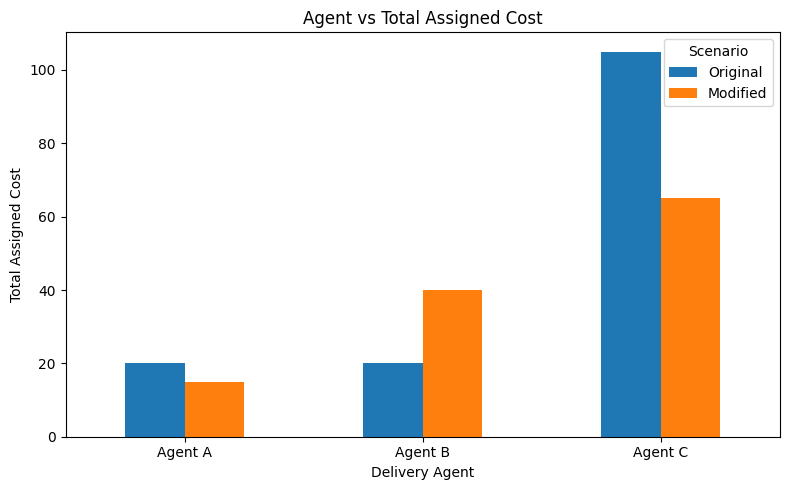

In [40]:

original_agent_cost = (
    allocation_df.groupby("Selected Agent")["Cost"]
    .sum().reindex(agents, fill_value=0)
)

modified_agent_cost = (
    modified_allocation.groupby("Selected Agent")["Cost"]
    .sum().reindex(agents, fill_value=0)
)

chart_data = pd.DataFrame({
    "Original": original_agent_cost,
    "Modified": modified_agent_cost
})

chart_data.plot(kind="bar", figsize=(8, 5))

plt.title("Agent vs Total Assigned Cost")
plt.xlabel("Delivery Agent")
plt.ylabel("Total Assigned Cost")
plt.xticks(rotation=0)
plt.legend(title="Scenario")
plt.tight_layout()
plt.show()


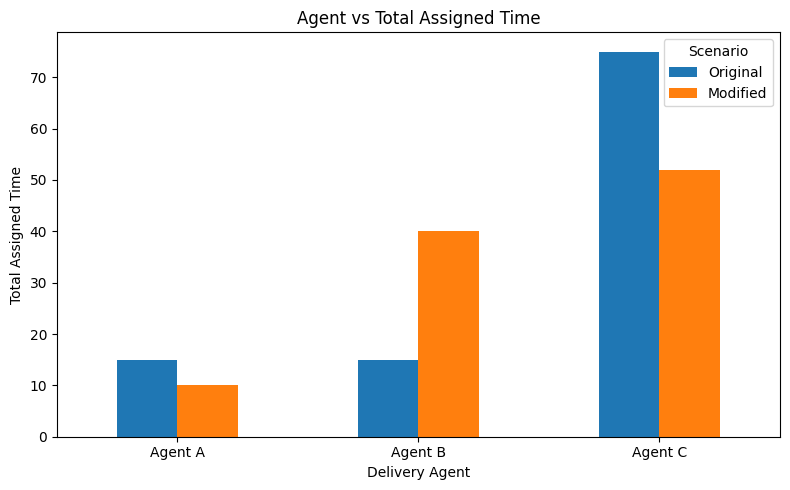

In [36]:

original_agent_time = (
    allocation_df.groupby("Selected Agent")["Time"]
    .sum().reindex(agents, fill_value=0)
)

modified_agent_time = (
    modified_allocation.groupby("Selected Agent")["Time"]
    .sum().reindex(agents, fill_value=0)
)

time_chart = pd.DataFrame({
    "Original": original_agent_time,
    "Modified": modified_agent_time
})

time_chart.plot(kind="bar", figsize=(8, 5))

plt.title("Agent vs Total Assigned Time")
plt.xlabel("Delivery Agent")
plt.ylabel("Total Assigned Time")
plt.xticks(rotation=0)
plt.legend(title="Scenario")
plt.tight_layout()
plt.show()


In [37]:
print("OBSERVATIONS")
print("1. PGP detects and resolves conflicts between agent plans.")
print("2. CNP announces tasks and collects bids from all agents.")
print("3. The manager selects the lowest-cost bidder for each task.")
print("4. All six tasks are allocated automatically.")
print("5. Modified costs can change task assignments and total cost.")
print("6. Bar charts compare agent costs and delivery times.")

OBSERVATIONS
1. PGP detects and resolves conflicts between agent plans.
2. CNP announces tasks and collects bids from all agents.
3. The manager selects the lowest-cost bidder for each task.
4. All six tasks are allocated automatically.
5. Modified costs can change task assignments and total cost.
6. Bar charts compare agent costs and delivery times.
